# **MÓDULO 19**
# Exercício: Estatística Aplicada

**Efetividade de Duas Estratégias de Ensino**

Imagine que uma escola esteja avaliando a eficácia de duas estratégias de ensino de matemática para alunos do ensino médio. Eles querem determinar se há uma diferença significativa no desempenho médio dos alunos entre as duas estratégias.

# **Hipóteses:**

* Hipótese nula (H0): A média das notas dos alunos na estratégia A é igual à média das notas dos alunos na estratégia B.
* Hipótese alternativa (H1): A média das notas na Estratégia B é maior do que a média das notas na Estratégia A.

# **Dados:**

* Amostra da Estratégia A: Notas de 50 alunos que receberam a Estratégia A.
* Amostra da Estratégia B: Notas de 50 alunos que receberam a Estratégia B.

Usaremos um teste Z para comparar as médias das notas entre as duas amostras.

Se o p-valor do teste Z for menor que um nível de significância pré-determinado (por exemplo, α = 0.05), rejeitamos a hipótese nula e concluímos que há uma diferença significativa nas médias das notas entre as duas estratégias de ensino.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

Os dados são criados a seguir:

In [5]:
# Definindo médias e desvios padrão para as notas nas duas estratégias
media_estrategia_A = 70
desvio_padrao_estrategia_A = 10

media_estrategia_B = 75
desvio_padrao_estrategia_B = 12

# Gerando as amostras de notas para cada estratégia de ensino da nossa base
np.random.seed(0)  # Para garantir a reprodutibilidade dos resultados
amostra_estrategia_A = np.random.normal(loc=media_estrategia_A, scale=desvio_padrao_estrategia_A, size=50)
amostra_estrategia_B = np.random.normal(loc=media_estrategia_B, scale=desvio_padrao_estrategia_B, size=50)

print("Notas da Estratégia A:", amostra_estrategia_A[:5])
print("Notas da Estratégia B:", amostra_estrategia_B[:5])

Notas da Estratégia A: [87.64052346 74.00157208 79.78737984 92.40893199 88.6755799 ]
Notas da Estratégia B: [64.25440127 79.64282997 68.87033835 60.83241379 74.66181326]


# 1) De acordo com as informações analisadas o nosso teste é unilateral á direita, esquerda ou bicaudal? Justifique.




O teste é unilateral à direita porque o enunciado definiu na hipótese alternativa (H1) o interesse exclusivo em provar se a média da Estratégia B é estritamente maior (>) do que a da Estratégia A, e não apenas se elas são diferentes.

# 2) Calcule as médias para as duas amostragens e as variâncias. Quais insights você pode retirar comparando os dados?

In [6]:
media_das_notas_da_Estratégia_A = np.mean(amostra_estrategia_A)
variancia_das_notas_da_Estratégia_A = np.var(amostra_estrategia_A)

media_das_notas_da_Estratégia_B = np.mean(amostra_estrategia_B)
variancia_das_notas_da_Estratégia_B = np.var(amostra_estrategia_B)

print("Média das notas da Estratégia A:", media_das_notas_da_Estratégia_A)
print("Variância das notas da Estratégia A:", variancia_das_notas_da_Estratégia_A)
print("Média das notas da Estratégia B:", media_das_notas_da_Estratégia_B)
print("Variância das notas da Estratégia B:", variancia_das_notas_da_Estratégia_B)


Média das notas da Estratégia A: 71.40559272313098
Variância das notas da Estratégia A: 126.68018446943104
Média das notas da Estratégia B: 74.74868110507046
Variância das notas da Estratégia B: 108.26062024217782


A Estratégia B não apenas gerou notas mais altas no geral (média maior), mas também foi mais consistente (variância menor). Uma variância menor no ensino é algo muito positivo, pois significa que a turma aprendeu de forma mais uniforme, com menos alunos ficando muito para trás ou tirando notas muito discrepantes do restante da sala.

# 3) Imprima os resultados da estatística do teste Z, p value e indique se rejeitaremos ou não a hipótese nula. Justifique sua resposta.

In [7]:
# Importando a ferramenta pronta para o Teste Z
from statsmodels.stats.weightstats import ztest

# Rodando o teste Z
# Colocamos a amostra B primeiro (x1) e a A depois (x2)
# O parâmetro 'alternative' define a direção do teste. 
# Como nossa H1 é que B é MAIOR que A (unilateral à direita), usamos 'larger' (maior)
estatistica_z, p_valor = ztest(x1=amostra_estrategia_B, x2=amostra_estrategia_A, alternative='larger')

print("Estatística Z:", estatistica_z)
print("Valor-P (p-value):", p_valor)

Estatística Z: 1.5267455833477102
Valor-P (p-value): 0.06341214386181693


O que esse teste acabou de provar é que essa diferença não foi forte o suficiente para termos certeza de que o método B é realmente superior. Nós apenas demos "sorte" com esses 50 alunos amostrados. Como não há evidências suficientes para declarar a Estratégia B como a grande vencedora, o "desmancha-prazeres" (H0) ganha: oficialmente, para a estatística, as duas estratégias de ensino têm a mesma efetividade e empatam.

# 4) Para finalizar monte o gráfico da distribuição da estatística do nosso teste Z e explique o que pode ser observado através dele.

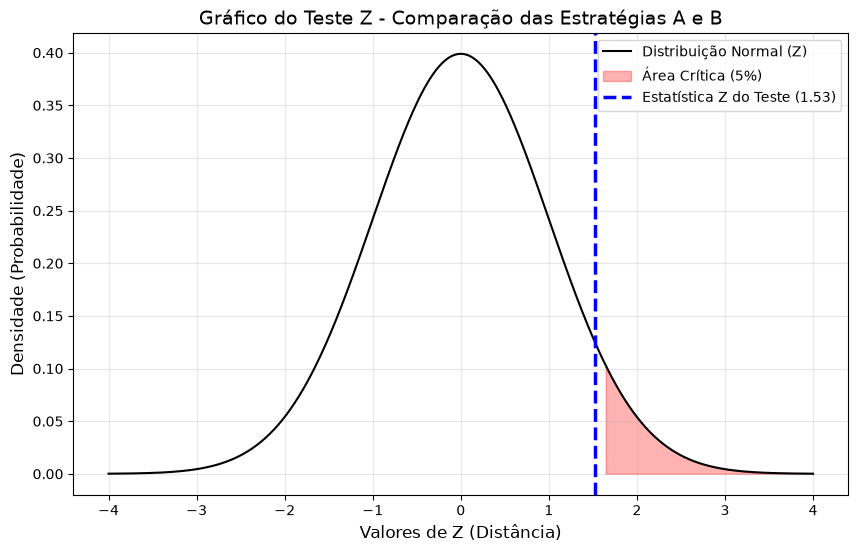

In [8]:
# 1. Criando a "pista": eixo X (valores de Z) e a curva de sino (eixo Y)
x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x, 0, 1)

plt.figure(figsize=(10, 6))
plt.plot(x, y, label='Distribuição Normal (Z)', color='black')

# 2. Definindo a linha de chegada (Z-crítico)
# Como o Nível de Significância é 0,05 (5%) e o teste é unilateral à direita,
# queremos achar o ponto que separa os 95% da esquerda dos 5% da direita.
alpha = 0.05
z_critico = stats.norm.ppf(1 - alpha) 

# 3. Pintando a "área de vitória" (Zona de Rejeição da Hipótese Nula) de vermelho
x_critico = np.linspace(z_critico, 4, 100)
y_critico = stats.norm.pdf(x_critico, 0, 1)
plt.fill_between(x_critico, y_critico, color='red', alpha=0.3, label=f'Área Crítica (5%)')

# 4. Marcando onde a Estratégia B realmente parou (nossa Estatística Z de ~1.52)
plt.axvline(estatistica_z, color='blue', linestyle='--', linewidth=2.5, label=f'Estatística Z do Teste ({estatistica_z:.2f})')

# Melhorando o visual do gráfico
plt.title('Gráfico do Teste Z - Comparação das Estratégias A e B', fontsize=14)
plt.xlabel('Valores de Z (Distância)', fontsize=12)
plt.ylabel('Densidade (Probabilidade)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)

# Mostrando o desenho final
plt.show()

O gráfico revela visualmente a nossa decisão estatística. A área vermelha representa a região de rejeição da Hipótese Nula (a "zona de vitória" da Estratégia B). Como a linha azul da nossa estatística Z (1,53) caiu fora dessa área crítica, temos a prova visual de que o resultado não foi extremo o suficiente. Portanto, isso confirma que não podemos rejeitar a Hipótese Nula, concluindo que não há diferença estatisticamente significativa entre as duas estratégias de ensino.